# Forecasting Monthly Gold Prices using the Box–Jenkins Methodology

**Data:** Monthly average price of standard gold in Mumbai (₹ per 10 grams), RBI–DBIE, **January 2000 – December 2020**

| Sample | Period | Months | Used for |
|---|---|---|---|
| Training | Jan 2000 – Dec 2019 | 240 | identification, estimation, diagnostic checking |
| Test | Jan 2020 – Dec 2020 | 12 | out-of-sample evaluation of the forecasts |
| Full | Jan 2000 – Dec 2020 | 252 | re-estimation of the chosen model and final forecast for 2021 |

The analysis follows the stages of the Box–Jenkins approach (Box, Jenkins, Reinsel & Ljung (2016), *Time Series Analysis: Forecasting and Control*, 5th ed.):

1. **Identification** – transform the series to stationarity, test for a unit root, and read the ACF/PACF (Ch. 6, §10.1).
2. **Estimation** – fit candidate ARIMA models by maximum likelihood and compare them with AIC/BIC (Ch. 7, §6.2.4).
3. **Diagnostic checking** – check that the residuals are white noise, and overfit as a check (Ch. 8).
4. **Forecasting** – evaluate forecasts on 2020, then refit on 2000–2020 and forecast 2021 (Ch. 5).

All values quoted in the report can be read from the printed outputs. Section 6 collects them in one place.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

## 0. Data

**Source:** Reserve Bank of India, Database on Indian Economy (DBIE), *Gold and Silver Prices*:
monthly average price of standard gold in Mumbai (₹ per 10 grams).

The loader accepts either DBIE export layout (Excel or CSV):

- **Layout A:** a `Month/Year` date column followed by the gold price column.
- **Layout B:** the DBIE report view, with financial-year blocks (e.g. `2025-26`), month rows `APR … MAR`
  and an `Average` row per year. Months APR–DEC belong to the first calendar year of the block, and JAN–MAR
  to the second. `Average` rows and the London/New York columns are ignored.

Only the assigned period, January 2000 – December 2020, is used. It is also saved as `gold_2000_2020.csv`,
the raw data file for submission.

In [2]:
FILE = "data.xlsx"   # DBIE export (Excel or CSV) in the same folder as this notebook

MONTHS = {m: i for i, m in enumerate(
    ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"], start=1)}

def to_number(x):
    # handles Indian digit grouping such as '1,42,605.83' and '-' for missing values
    return pd.to_numeric(str(x).replace(",", "").strip(), errors="coerce")

def load_gold(path):
    read = pd.read_csv if path.lower().endswith(".csv") else pd.read_excel
    sheet = read(path, header=None, dtype=object)
    text = sheet.apply(lambda col: col.fillna("").astype(str).str.strip())

    header = text.isin(["Month/Year"])
    if header.values.any():
        # Layout A: 'Month/Year' column of dates, gold price in the next column
        r, c = np.argwhere(header.values)[0]
        dates = pd.to_datetime(sheet.iloc[r + 1:, c], errors="coerce")
        prices = sheet.iloc[r + 1:, c + 1].map(to_number)
        s = pd.Series(prices.values, index=dates.values)
    else:
        # Layout B: financial-year blocks such as '2025-26', then month rows APR ... MAR
        upper = text.apply(lambda col: col.str.upper())
        label_col = upper.isin(MONTHS.keys()).sum().idxmax()
        is_month = upper[label_col].isin(MONTHS.keys())
        # gold price = first column to the right of the labels that holds numbers on the month rows
        pos = list(sheet.columns).index(label_col)
        price_col = next(c for c in sheet.columns[pos + 1:]
                         if sheet.loc[is_month, c].map(to_number).notna().mean() > 0.5)
        records, fy_start = {}, None
        for label, value in zip(upper[label_col], sheet[price_col]):
            fy = re.match(r"^(\d{4})\s*-\s*\d{2,4}$", label)
            if fy:
                fy_start = int(fy.group(1))
            elif label in MONTHS and fy_start is not None:
                month = MONTHS[label]
                year = fy_start if month >= 4 else fy_start + 1
                records[pd.Timestamp(year, month, 1)] = to_number(value)
        s = pd.Series(records)

    s = s[s.index.notna()].dropna().sort_index()
    s = s[~s.index.duplicated()]
    s.index = pd.DatetimeIndex(s.index, name="Date")
    return s.asfreq("MS").rename("Gold_Price")

full = load_gold(FILE)
print(f"Loaded {len(full)} months: {full.index[0]:%b %Y} – {full.index[-1]:%b %Y}")

sample = full.loc["2000-01-01":"2020-12-01"]     # assigned period
train  = sample.loc[:"2019-12-01"]               # identification + estimation
test   = sample.loc["2020-01-01":]               # out-of-sample evaluation

for name, s in [("Full (assigned)", sample), ("Training", train), ("Test", test)]:
    print(f"{name:<16}: {s.index[0]:%b %Y} – {s.index[-1]:%b %Y}  ({len(s)} obs, {s.isna().sum()} missing)")
print(f"\nCheck against DBIE: Jan 2000 = {sample.iloc[0]:,.2f},  Dec 2020 = {sample.iloc[-1]:,.2f}")

sample.to_csv("gold_2000_2020.csv", header=True)   # raw data file for submission

Loaded 437 months: Apr 1990 – Aug 2026
Full (assigned) : Jan 2000 – Dec 2020  (252 obs, 0 missing)
Training        : Jan 2000 – Dec 2019  (240 obs, 0 missing)
Test            : Jan 2020 – Dec 2020  (12 obs, 0 missing)

Check against DBIE: Jan 2000 = 4,508.91,  Dec 2020 = 49,443.86


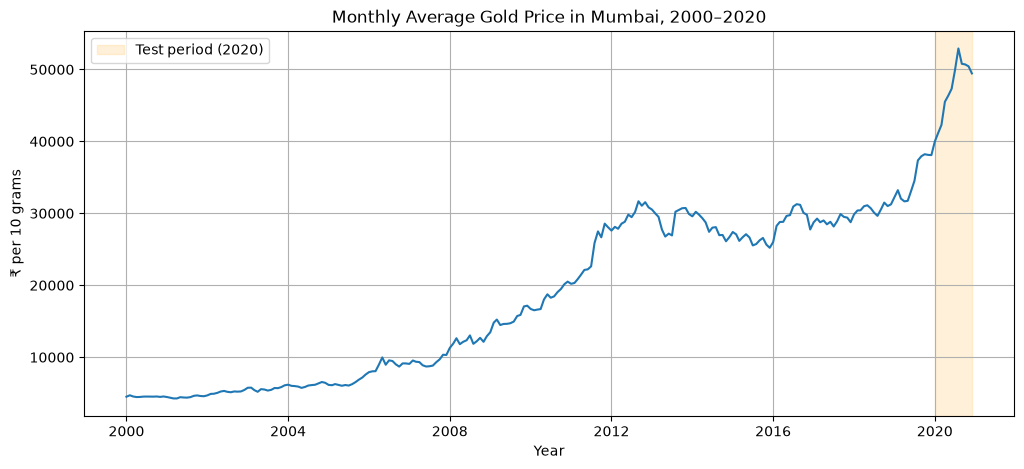

count      240.00
mean     17865.94
std      10857.24
min       4267.17
25%       6150.08
50%      16653.44
75%      28771.13
max      38213.55
Name: Gold_Price, dtype: float64

In [3]:
fig, ax = plt.subplots()
ax.plot(sample.index, sample, lw=1.5)
ax.axvspan(test.index[0], test.index[-1], color="orange", alpha=0.15, label="Test period (2020)")
ax.set(title="Monthly Average Gold Price in Mumbai, 2000–2020",
       xlabel="Year", ylabel="₹ per 10 grams")
ax.legend()
plt.show()

train.describe().round(2)

The price series shows a strong upward trend, so its mean is not constant. The size of the month-to-month
fluctuations also grows as the price rises, so the variance is not constant either. The series is non-stationary
in both mean and variance.

## 1. Identification (training sample, 2000–2019)

### 1.1 Log transformation and differencing

When it is the *percentage* rather than the absolute fluctuation that is stable, Box–Jenkins recommend analysing
the logarithm of the series (§4.1.3, p. 96). The first difference of the log price,

$$
w_t = \nabla \ln P_t = \ln P_t - \ln P_{t-1},
$$

is the continuously compounded monthly return on gold. The book uses the same transformation for weekly
S&P 500 returns (§10.2.4).

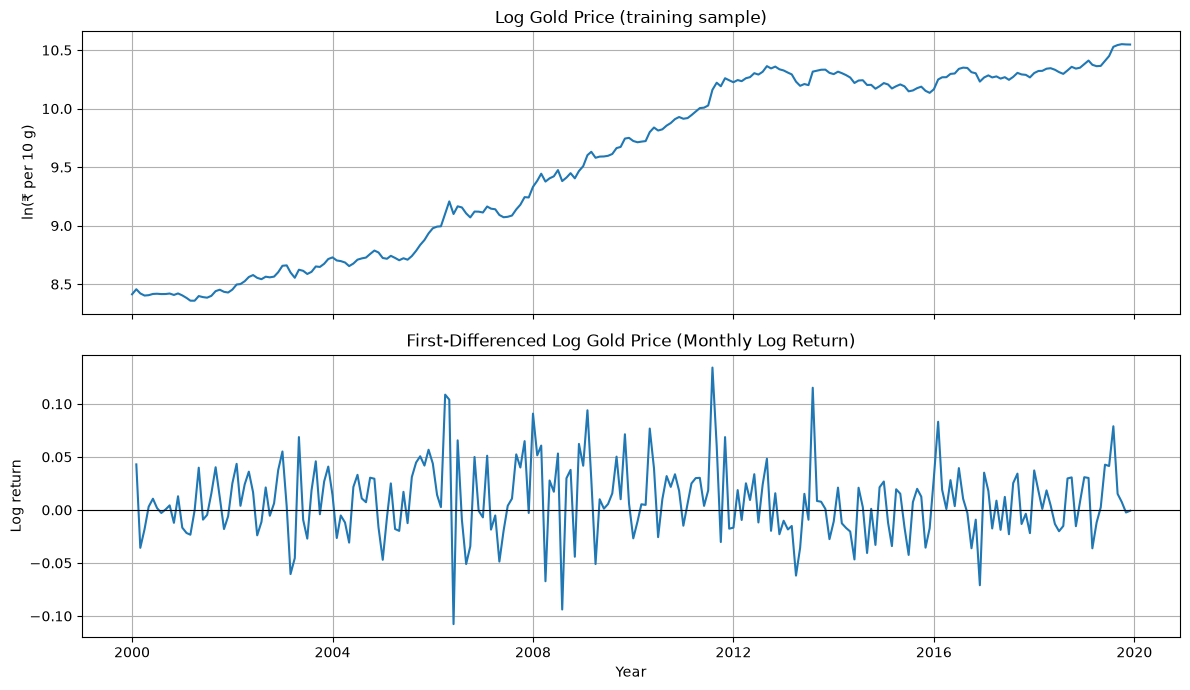

count    239.0000
mean       0.0089
std        0.0346
min       -0.1077
25%       -0.0132
50%        0.0074
75%        0.0299
max        0.1342
Name: Log_Return, dtype: float64

In [4]:
log_train = np.log(train).rename("Log_Price")
ret_train = log_train.diff().dropna().rename("Log_Return")

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(log_train)
ax[0].set(title="Log Gold Price (training sample)", ylabel="ln(₹ per 10 g)")
ax[1].plot(ret_train)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set(title="First-Differenced Log Gold Price (Monthly Log Return)",
          xlabel="Year", ylabel="Log return")
plt.tight_layout()
plt.show()

ret_train.describe().round(4)

### 1.2 Unit-root test (Augmented Dickey–Fuller, §10.1)

$$
H_0: \text{the series has a unit root (non-stationary)} \qquad
H_1: \text{the series is stationary}
$$

$H_0$ is rejected when the p-value is below 0.05, or equivalently when the test statistic is more negative than
the critical value. The log level is tested with a constant and a linear trend, because it trends. The first
difference is tested with a constant only.

In [5]:
def adf_report(series, name, regression="c"):
    stat, pvalue, usedlag, nobs, crit, _ = adfuller(series.dropna(), regression=regression, autolag="AIC")
    print(f"ADF test – {name}  (deterministic terms: '{regression}')")
    print(f"  ADF statistic : {stat:.3f}")
    print(f"  p-value       : {pvalue:.3g}")
    print(f"  lags used     : {usedlag}   observations: {nobs}")
    for level, value in crit.items():
        print(f"  critical {level:>3} : {value:.3f}")
    verdict = "reject H0 → stationary" if pvalue < 0.05 else "fail to reject H0 → unit root (non-stationary)"
    print(f"  Conclusion at 5%: {verdict}\n")
    return stat, pvalue

adf_level = adf_report(log_train, "log gold price (level)", regression="ct")
adf_diff  = adf_report(ret_train, "first-differenced log gold price", regression="c")

ADF test – log gold price (level)  (deterministic terms: 'ct')
  ADF statistic : -1.097
  p-value       : 0.93
  lags used     : 0   observations: 239
  critical  1% : -3.997
  critical  5% : -3.429
  critical 10% : -3.138
  Conclusion at 5%: fail to reject H0 → unit root (non-stationary)

ADF test – first-differenced log gold price  (deterministic terms: 'c')
  ADF statistic : -14.195
  p-value       : 1.83e-26
  lags used     : 0   observations: 238
  critical  1% : -3.458
  critical  5% : -2.874
  critical 10% : -2.573
  Conclusion at 5%: reject H0 → stationary



If the log level fails to reject $H_0$ and its first difference rejects it, one difference is enough to reach
stationarity, and the order of integration is **d = 1**.

### 1.3 ACF and PACF of the stationary series (§6.2)

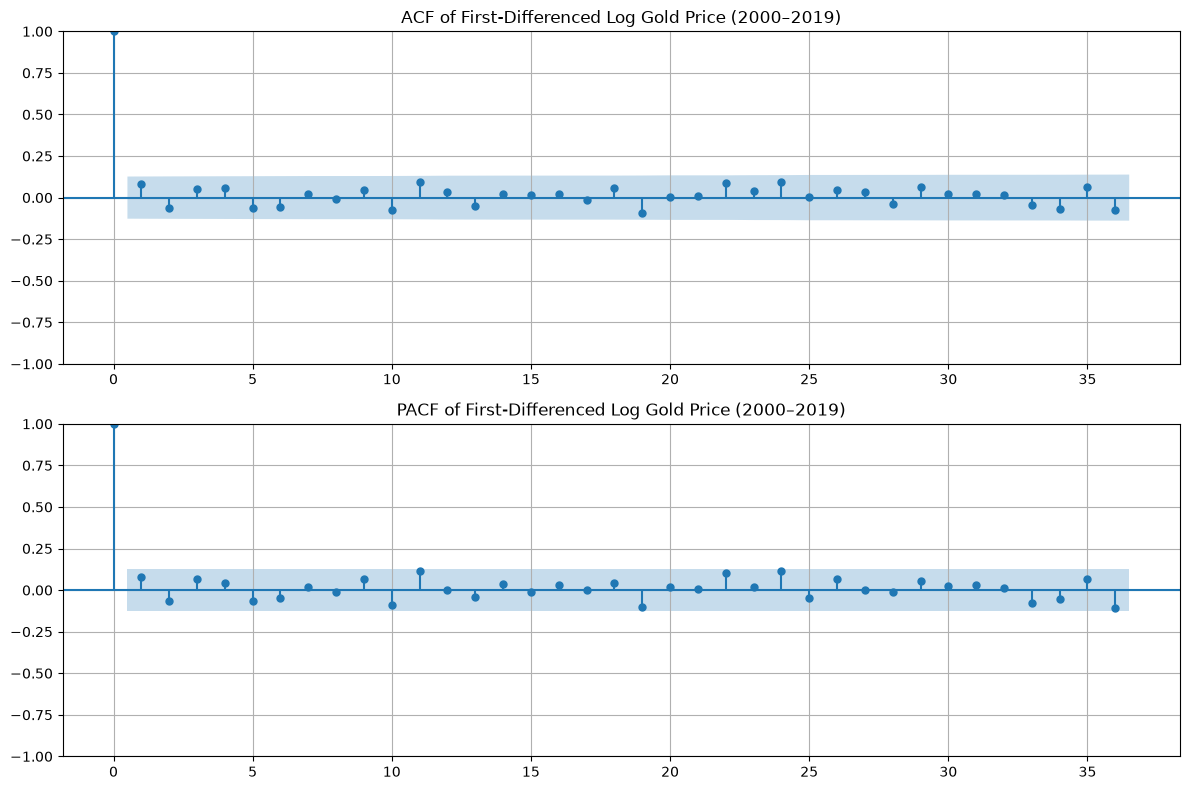

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(ret_train, lags=36, ax=ax[0])
ax[0].set_title("ACF of First-Differenced Log Gold Price (2000–2019)")
plot_pacf(ret_train, lags=36, ax=ax[1], method="ywm")
ax[1].set_title("PACF of First-Differenced Log Gold Price (2000–2019)")
plt.tight_layout()
plt.show()

The approximate 95% bounds are $\pm 2/\sqrt{n}$ (§6.2.2). If almost all autocorrelations and partial
autocorrelations lie inside the bounds, with no cut-off or decay pattern and no spikes at the seasonal lags 12, 24 or
36, the differenced series is close to white noise. The tentative model is then **ARIMA(0,1,0)**, a random walk
for the log price, possibly with a drift.

## 2. Estimation

### 2.1 Drift term

In Box–Jenkins notation, a drift is the constant $\theta_0$ in $\nabla \ln P_t = \theta_0 + a_t$. The book advises
taking $\theta_0 = 0$ "unless such an assumption is inconsistent with the data" (§4.1.3, p. 95). Whether the drift is
needed is therefore tested directly.

In `statsmodels`, a constant cannot be added directly when d = 1, because differencing would remove it. A drift is
specified as `trend="t"`, a linear trend in the level, which becomes $\theta_0$ after differencing.

In [7]:
rw       = ARIMA(log_train, order=(0, 1, 0)).fit()
rw_drift = ARIMA(log_train, order=(0, 1, 0), trend="t").fit()

display(pd.DataFrame({"AIC": [rw.aic, rw_drift.aic], "BIC": [rw.bic, rw_drift.bic]},
                     index=["ARIMA(0,1,0)", "ARIMA(0,1,0) + drift"]).round(2))
print(f"Drift θ0 = {rw_drift.params['x1']:.5f},  z = {rw_drift.tvalues['x1']:.2f},  p = {rw_drift.pvalues['x1']:.4f}")

,AIC,BIC
"ARIMA(0,1,0)",-912.90,-909.43
"ARIMA(0,1,0) + drift",-926.35,-919.40


Drift θ0 = 0.00892,  z = 3.94,  p = 0.0001


If the drift is significant and lowers both AIC and BIC, all candidate models below include it.

### 2.2 Candidate models

Following the overfitting idea in §8.1.2, the tentative ARIMA(0,1,0) + drift is extended by one parameter at
a time, giving **ARIMA(1,1,0)** and **ARIMA(0,1,1)**. **ARIMA(1,1,1)** and **ARIMA(2,1,1)** add AR and MA terms
together. The book warns that this risks near-cancelling common factors, i.e. *parameter redundancy* (§7.3.5,
p. 240). They are included to show that warning in practice.

Models are compared with AIC and BIC (§6.2.4, p. 193). BIC penalises additional parameters more heavily, so
the model it selects is never larger than the one AIC selects.

In [8]:
candidates = [(0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1), (2, 1, 1)]

fits, rows = {}, []
for order in candidates:
    name = "ARIMA({},{},{}) + drift".format(*order)
    res = ARIMA(log_train, order=order, trend="t").fit()
    fits[name] = res
    rows.append({"Model": name, "Parameters": len(res.params),
                 "Log-likelihood": res.llf, "AIC": res.aic, "BIC": res.bic})

ic_table = pd.DataFrame(rows).set_index("Model")
ic_table.round(3)

,Parameters,Log-likelihood,AIC,BIC
Model,,,,
"ARIMA(0,1,0) + drift",2,465.176,-926.353,-919.400
"ARIMA(1,1,0) + drift",3,465.957,-925.913,-915.484
"ARIMA(0,1,1) + drift",3,466.082,-926.164,-915.734
"ARIMA(1,1,1) + drift",4,466.558,-925.115,-911.209
"ARIMA(2,1,1) + drift",5,465.971,-921.942,-904.560


In [9]:
coef_table = pd.concat(
    {name: pd.DataFrame({"coef": res.params, "std err": res.bse, "p-value": res.pvalues})
     for name, res in fits.items()}
)
coef_table.round(4)

coef  std err  p-value
ARIMA(0,1,0) + drift x1      0.0089   0.0023   0.0001
                     sigma2  0.0012   0.0001   0.0000
ARIMA(1,1,0) + drift x1      0.0089   0.0025   0.0004
                     ar.L1   0.0807   0.0539   0.1346
                     sigma2  0.0012   0.0001   0.0000
ARIMA(0,1,1) + drift x1      0.0089   0.0025   0.0003
                     ma.L1   0.0928   0.0555   0.0942
                     sigma2  0.0012   0.0001   0.0000
ARIMA(1,1,1) + drift x1      0.0089   0.0024   0.0002
                     ar.L1  -0.4620   0.3587   0.1977
                     ma.L1   0.5579   0.3384   0.0992
                     sigma2  0.0012   0.0001   0.0000
ARIMA(2,1,1) + drift x1      0.0089   0.0025   0.0004
                     ar.L1  -0.8896   0.3902   0.0226
                     ar.L2   0.0757   0.0671   0.2588
                     ma.L1   0.9706   0.3777   0.0102
                     sigma2  0.0012   0.0001   0.0000

Things to look for in these tables:

- whether the AR(1) or MA(1) term added by overfitting is significant at 5%. If not, the extension is not supported;
- whether ARIMA(1,1,1) and ARIMA(2,1,1) show large standard errors and insignificant, offsetting AR and MA
  coefficients, the sign of parameter redundancy (§7.3.5);
- which model has the lowest BIC, and how close its AIC is to the others. An AIC difference below about 2 is usually
  treated as negligible.

## 3. Diagnostic checking (§8.2)

If a model is adequate, its residuals should be white noise. The **Ljung–Box portmanteau test** (§8.2.2, p. 289)
uses

$$
\tilde Q = n(n+2)\sum_{k=1}^{K}\frac{r_k^2(\hat a)}{n-k} \sim \chi^2_{K-p-q},
\qquad H_0: \text{residuals are white noise}.
$$

A p-value above 0.05 means there is no evidence of remaining autocorrelation.

**Note on the first residual.** For a model with d = 1, `statsmodels` cannot predict the first observation,
so the first residual equals the first log price itself (≈ 8.4). Monthly residuals are around 0.035, so this single
value is an extreme outlier. Left in, it swamps the test and drives every p-value to 1.0 regardless of the data.
The first *d* residuals are therefore dropped before testing.

In [10]:
print("First three residuals of ARIMA(0,1,0) + drift:")
print(fits["ARIMA(0,1,0) + drift"].resid.iloc[:3].round(4))
print("\nLjung–Box p-values WITH the first residual (incorrect – shown only for comparison):")
print(acorr_ljungbox(fits["ARIMA(0,1,0) + drift"].resid, lags=[6, 12], return_df=True)["lb_pvalue"].round(4))

First three residuals of ARIMA(0,1,0) + drift:
Date
2000-01-01    8.4049
2000-02-01    0.0340
2000-03-01   -0.0446
Freq: MS, dtype: float64

Ljung–Box p-values WITH the first residual (incorrect – shown only for comparison):
6     1.0
12    1.0
Name: lb_pvalue, dtype: float64


In [11]:
def ljung_box(res, lags=(6, 12, 18, 24)):
    p, d, q = res.model.order
    resid = res.resid.iloc[d:]                 # drop the first d residuals (see note above)
    return acorr_ljungbox(resid, lags=list(lags), model_df=p + q, return_df=True)

lb_table = pd.DataFrame({name: ljung_box(res)["lb_pvalue"] for name, res in fits.items()}).T
lb_table.columns = [f"p-value (lag {lag})" for lag in lb_table.columns]
lb_table.round(4)

,p-value (lag 6),p-value (lag 12),p-value (lag 18),p-value (lag 24)
"ARIMA(0,1,0) + drift",0.4391,0.5753,0.8296,0.7092
"ARIMA(1,1,0) + drift",0.4545,0.5107,0.7629,0.6509
"ARIMA(0,1,1) + drift",0.4957,0.5216,0.7650,0.6454
"ARIMA(1,1,1) + drift",0.5352,0.5345,0.7691,0.5738
"ARIMA(2,1,1) + drift",0.2045,0.3651,0.6533,0.5338


### 3.1 Model selection

**Selection rule:** among the models whose residuals pass the Ljung–Box test at every lag (all p-values > 0.05),
choose the one with the **lowest BIC**. This favours the most parsimonious adequate model, as Box–Jenkins
recommend. The choice uses only the 2000–2019 training data, so the 2020 test below is genuinely out-of-sample.

In [12]:
adequate = lb_table.min(axis=1) > 0.05
pool = ic_table[adequate] if adequate.any() else ic_table
final_name = pool["BIC"].idxmin()
final = fits[final_name]
final_order = final.model.order

summary_sel = ic_table[["AIC", "BIC"]].assign(**{"Passes Ljung–Box": adequate})
display(summary_sel.round(3))
print("Selected model:", final_name)

,AIC,BIC,Passes Ljung–Box
Model,,,
"ARIMA(0,1,0) + drift",-926.353,-919.400,True
"ARIMA(1,1,0) + drift",-925.913,-915.484,True
"ARIMA(0,1,1) + drift",-926.164,-915.734,True
"ARIMA(1,1,1) + drift",-925.115,-911.209,True
"ARIMA(2,1,1) + drift",-921.942,-904.560,True


Selected model: ARIMA(0,1,0) + drift


                               SARIMAX Results                                
Dep. Variable:              Log_Price   No. Observations:                  240
Model:                 ARIMA(0, 1, 0)   Log Likelihood                 465.176
Date:                Fri, 23 Oct 2026   AIC                           -926.353
Time:                        19:25:08   BIC                           -919.400
Sample:                    01-01-2000   HQIC                          -923.551
                         - 12-01-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0089      0.002      3.944      0.000       0.004       0.013
sigma2         0.0012    8.7e-05     13.726      0.000       0.001       0.001
Ljung-Box (L1) (Q):                   1.57   Jarque-

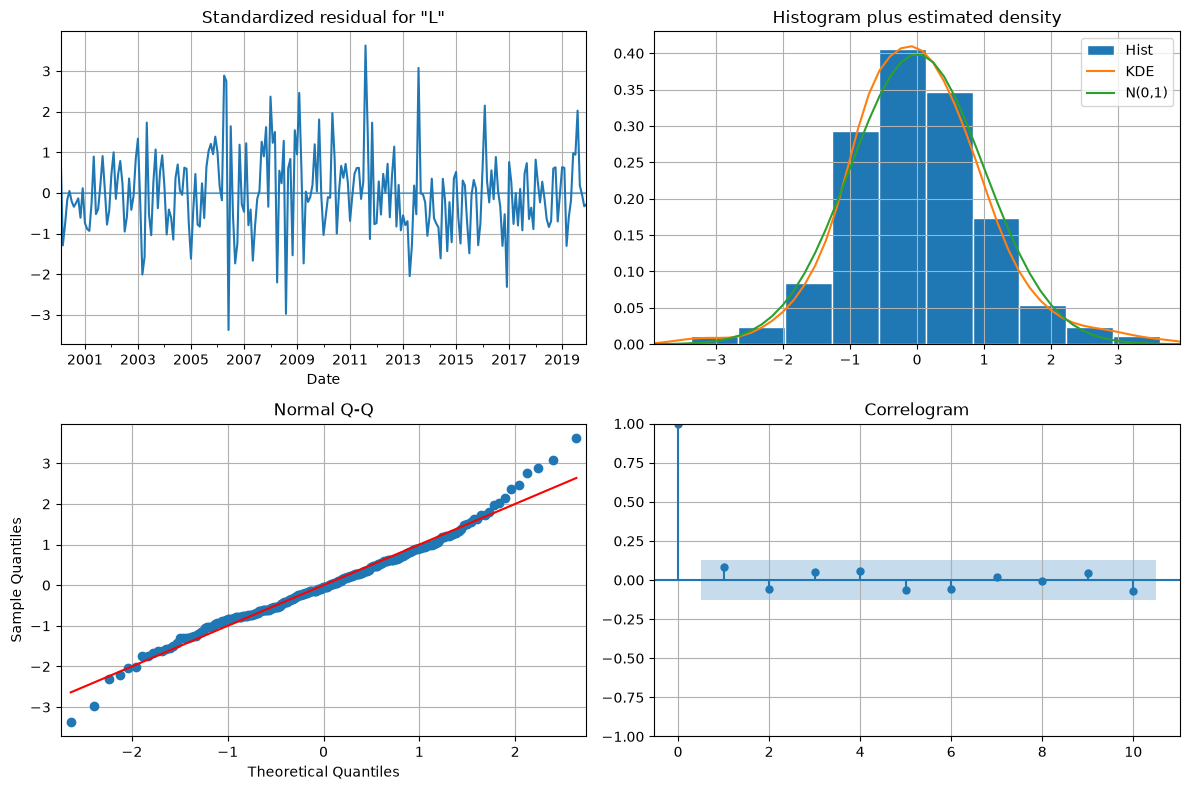

In [13]:
print(final.summary())
final.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [14]:
mu = final.params["x1"]
sigma = np.sqrt(final.params["sigma2"])
arma = {k: v for k, v in final.params.items() if k.startswith(("ar.", "ma."))}

print(f"Selected model: {final_name}")
print(f"  drift θ0 (mean monthly log return) : {mu:.4f}")
for k, v in arma.items():
    print(f"  {k:<6}                            : {v:.4f}  (p = {final.pvalues[k]:.3f})")
print(f"  shock std. dev. σ_a                : {sigma:.4f}  ({sigma:.2%} per month)")
print(f"  implied average annual growth      : {np.exp(12 * mu) - 1:.1%}")

Selected model: ARIMA(0,1,0) + drift
  drift θ0 (mean monthly log return) : 0.0089
  shock std. dev. σ_a                : 0.0346  (3.46% per month)
  implied average annual growth      : 11.3%


**Reading the diagnostics**

- **Autocorrelation:** the Ljung–Box table and the residual correlogram should show no remaining serial correlation.
- **Heteroskedasticity:** the *Heteroskedasticity (H)* line in the model summary tests whether the residual
  variance changes over the sample. A p-value above 0.05 means the log transform has stabilised the variance.
- **Normality:** the *Jarque–Bera* line tests normality. Financial returns usually have fat tails (kurtosis above 3),
  so the test often rejects. This does not affect the point forecasts, but the normal-based forecast intervals may
  be too narrow in the tails. The book discusses this for asset returns in §10.2.4.

**Economic interpretation.** With a drift and no significant ARMA terms, the model is a random walk with drift in
the log price, $\nabla \ln P_t = \theta_0 + a_t$. Gold prices then grow on average at the rate $\theta_0$ per month,
and past returns carry no further information about future returns. This is consistent with weak-form efficiency of
the gold market.

## 4. Forecast evaluation on 2020 (test sample)

The model estimated on 2000–2019 is used to forecast January–December 2020, 1 to 12 months ahead from December
2019, with 95% probability limits (§5.2.3). Forecasts are converted back to rupees with $\exp(\cdot)$. Strictly, this
gives the median rather than the mean forecast of the price, but the difference is small at this volatility.

In [15]:
def forecast_errors(actual, pred):
    actual, pred = np.asarray(actual), np.asarray(pred)
    return {"MAE": float(mean_absolute_error(actual, pred)),
            "RMSE": float(np.sqrt(mean_squared_error(actual, pred))),
            "MAPE (%)": float(np.mean(np.abs((actual - pred) / actual)) * 100)}

def price_forecast(res, steps, alpha=0.05):
    fc = res.get_forecast(steps=steps)
    ci = fc.conf_int(alpha=alpha)
    return pd.DataFrame({"Forecast": np.exp(fc.predicted_mean),
                         "Lower_95": np.exp(ci.iloc[:, 0]),
                         "Upper_95": np.exp(ci.iloc[:, 1])})

test_fc = price_forecast(final, steps=len(test))
test_fc["Actual"] = test
test_fc["Error (%)"] = (test_fc["Actual"] - test_fc["Forecast"]) / test_fc["Actual"] * 100

errors_test = forecast_errors(test_fc["Actual"], test_fc["Forecast"])
inside = test_fc["Actual"].between(test_fc["Lower_95"], test_fc["Upper_95"])

for k, v in errors_test.items():
    print(f"{k:>9}: {v:,.2f}")
print(f"Actual values inside the 95% interval: {inside.sum()} of {len(inside)}")
test_fc.round(1)

      MAE: 6,845.87
     RMSE: 7,481.74
 MAPE (%): 14.04
Actual values inside the 95% interval: 7 of 12


,Forecast,Lower_95,Upper_95,Actual,Error (%)
2020-01-01,38433.0,35916.1,41126.3,39983.8,3.9
2020-02-01,38777.5,35235.5,42675.6,41195.2,5.9
2020-03-01,39125.1,34794.2,43995.1,42285.3,7.5
2020-04-01,39475.8,34474.7,45202.4,45504.4,13.2
2020-05-01,39829.6,34232.0,46342.6,46343.3,14.1
2020-06-01,40186.6,34043.1,47438.8,47314.7,15.1
2020-07-01,40546.9,33894.7,48504.5,49878.4,18.7
2020-08-01,40910.3,33778.0,49548.6,52917.2,22.7
2020-09-01,41277.0,33687.0,50577.1,50783.6,18.7
2020-10-01,41647.0,33617.4,51594.4,50697.8,17.9


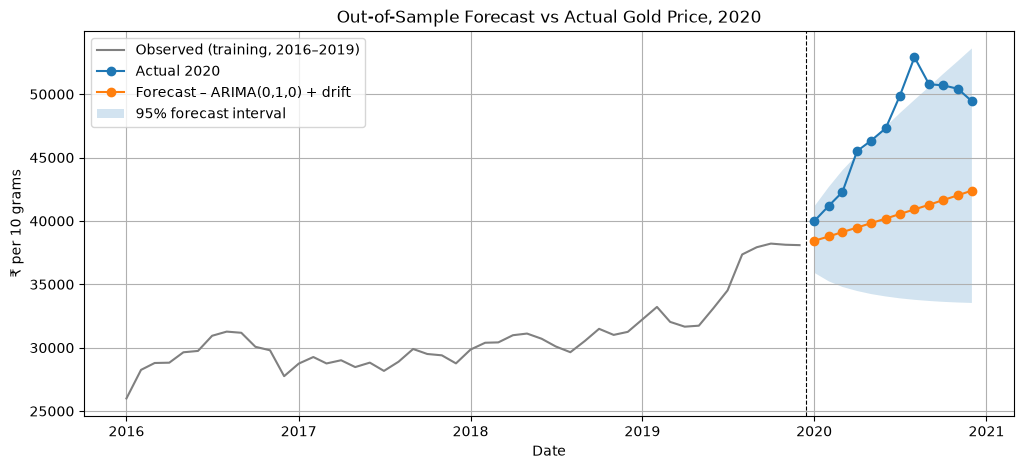

In [16]:
history = train.loc["2016-01-01":]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(history.index, history, color="grey", label="Observed (training, 2016–2019)")
ax.plot(test_fc.index, test_fc["Actual"], marker="o", label="Actual 2020")
ax.plot(test_fc.index, test_fc["Forecast"], marker="o", label=f"Forecast – {final_name}")
ax.fill_between(test_fc.index, test_fc["Lower_95"], test_fc["Upper_95"],
                alpha=0.2, label="95% forecast interval")
ax.axvline(pd.Timestamp("2019-12-15"), color="black", ls="--", lw=0.8)
ax.set(title="Out-of-Sample Forecast vs Actual Gold Price, 2020",
       xlabel="Date", ylabel="₹ per 10 grams")
ax.legend()
plt.show()

The forecast extends the 2000–2019 average growth rate. In 2020, gold prices rose much faster than that, peaking in
August 2020 amid pandemic-driven safe-haven demand. A constant-drift model therefore under-predicts most of 2020.
The size of the gap and how many months fall outside the 95% interval are shown above. This is the main weakness to
discuss in the report: the model cannot anticipate shocks or turning points.

### 4.1 Robustness: all candidates on 2020

This is a check, not a selection criterion.

In [17]:
oos = pd.DataFrame({name: forecast_errors(test, np.exp(res.get_forecast(steps=len(test)).predicted_mean))
                    for name, res in fits.items()}).T
oos.insert(0, "BIC", ic_table["BIC"])
oos.round(2).sort_values("RMSE")

,BIC,MAE,RMSE,MAPE (%)
"ARIMA(1,1,1) + drift",-911.21,6838.39,7474.26,14.03
"ARIMA(0,1,0) + drift",-919.40,6845.87,7481.74,14.04
"ARIMA(2,1,1) + drift",-904.56,6871.69,7505.60,14.10
"ARIMA(0,1,1) + drift",-915.73,6876.38,7509.62,14.11
"ARIMA(1,1,0) + drift",-915.48,6878.52,7511.85,14.11


### 4.2 Rolling one-step-ahead forecasts (updating, §5.2.2)

In practice a forecast is updated each month as new data arrive. In this exercise the parameters are kept at their
2000–2019 estimates, each actual 2020 price is added to the information set, and the next month is forecast.

In [18]:
log_test = np.log(test).rename(log_train.name)

res_roll, one_step = final, []
for date in log_test.index:
    one_step.append(np.exp(res_roll.forecast(steps=1).iloc[0]))
    res_roll = res_roll.append(log_test.loc[[date]], refit=False)
one_step = pd.Series(one_step, index=test.index, name="One-step forecast")

errors_roll = forecast_errors(test, one_step)
pd.DataFrame({"1- to 12-step-ahead (from Dec 2019)": errors_test,
              "Rolling 1-step-ahead": errors_roll}).T.round(2)

,MAE,RMSE,MAPE (%)
1- to 12-step-ahead (from Dec 2019),6845.87,7481.74,14.04
Rolling 1-step-ahead,1416.03,1663.07,2.98


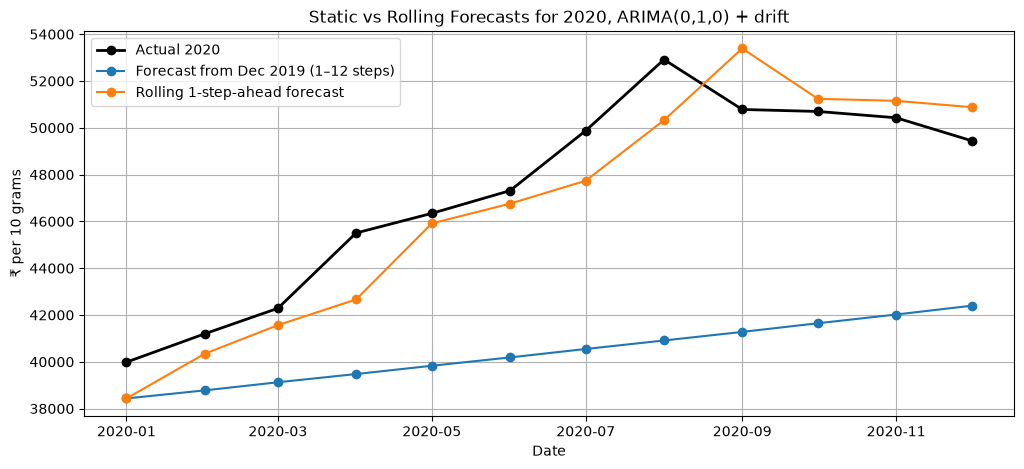

In [19]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test.index, test, marker="o", lw=2, color="black", label="Actual 2020")
ax.plot(test.index, test_fc["Forecast"], marker="o", label="Forecast from Dec 2019 (1–12 steps)")
ax.plot(test.index, one_step, marker="o", label="Rolling 1-step-ahead forecast")
ax.set(title=f"Static vs Rolling Forecasts for 2020, {final_name}",
       xlabel="Date", ylabel="₹ per 10 grams")
ax.legend()
plt.show()

For a random walk with drift, the one-step forecast is simply this month's price grown by the drift,
$\hat P_{t+1} = P_t\,e^{\hat\theta_0}$. It follows the actual series with a one-month lag and is much more accurate
than forecasts made 12 months in advance.

## 5. Final model: re-estimation on 2000–2020 and forecast for 2021

The selected specification is re-estimated on the full assigned sample (252 months), and the next 12 months are
forecast with 95% probability limits. These are genuine *ex-ante* forecasts beyond the data.

In [20]:
log_sample = np.log(sample).rename("Log_Price")
final_full = ARIMA(log_sample, order=final_order, trend="t").fit()
print(final_full.summary())
print("\nLjung–Box (full sample):")
print(ljung_box(final_full).round(4))

                               SARIMAX Results                                
Dep. Variable:              Log_Price   No. Observations:                  252
Model:                 ARIMA(0, 1, 0)   Log Likelihood                 488.388
Date:                Fri, 23 Oct 2026   AIC                           -972.776
Time:                        19:25:16   BIC                           -965.725
Sample:                    01-01-2000   HQIC                          -969.939
                         - 12-01-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0095      0.002      4.327      0.000       0.005       0.014
sigma2         0.0012   8.65e-05     13.819      0.000       0.001       0.001
Ljung-Box (L1) (Q):                   2.03   Jarque-

In [21]:
fc_2021 = price_forecast(final_full, steps=12)
fc_2021.index.name = "Date"
fc_2021.round(0)

,Forecast,Lower_95,Upper_95
Date,,,
2021-01-01,49918.0,46648.0,53417.0
2021-02-01,50396.0,45791.0,55464.0
2021-03-01,50879.0,45245.0,57214.0
2021-04-01,51366.0,44857.0,58820.0
2021-05-01,51858.0,44568.0,60341.0
2021-06-01,52355.0,44349.0,61807.0
2021-07-01,52857.0,44183.0,63234.0
2021-08-01,53363.0,44057.0,64635.0
2021-09-01,53875.0,43965.0,66018.0


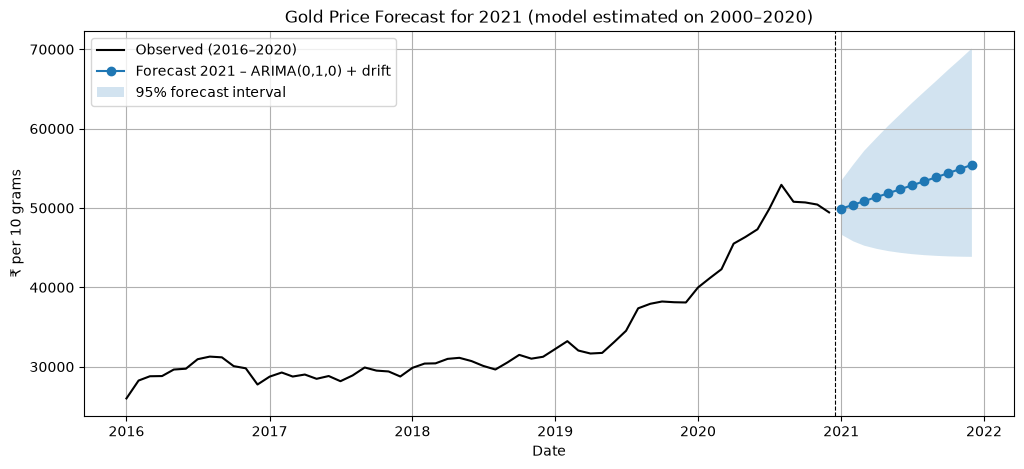

In [22]:
history = sample.loc["2016-01-01":]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(history.index, history, color="black", label="Observed (2016–2020)")
ax.plot(fc_2021.index, fc_2021["Forecast"], marker="o", label=f"Forecast 2021 – {final_name}")
ax.fill_between(fc_2021.index, fc_2021["Lower_95"], fc_2021["Upper_95"],
                alpha=0.2, label="95% forecast interval")
ax.axvline(pd.Timestamp("2020-12-15"), color="black", ls="--", lw=0.8)
ax.set(title="Gold Price Forecast for 2021 (model estimated on 2000–2020)",
       xlabel="Date", ylabel="₹ per 10 grams")
ax.legend()
plt.show()

The forecast path rises at the estimated drift rate, and the 95% interval widens with the horizon. For a random
walk, the forecast-error variance grows linearly with the lead time (§5.2.3).

*Optional:* if the DBIE file also contains 2021, the cell below compares the 2021 forecast with what actually
happened. This uses data outside the assigned 2000–2020 period, so mention it in the report only as a side note.

In [23]:
actual_2021 = full.loc["2021-01-01":"2021-12-01"]
if len(actual_2021) == 12:
    check = fc_2021.assign(Actual=actual_2021)
    print({k: round(v, 2) for k, v in forecast_errors(check["Actual"], check["Forecast"]).items()})
    display(check.round(0))
else:
    print("2021 data not in the file – skipped.")

{'MAE': 5267.95, 'RMSE': 5634.3, 'MAPE (%)': 11.18}


,Forecast,Lower_95,Upper_95,Actual
Date,,,,
2021-01-01,49918.0,46648.0,53417.0,49612.0
2021-02-01,50396.0,45791.0,55464.0,47107.0
2021-03-01,50879.0,45245.0,57214.0,44648.0
2021-04-01,51366.0,44857.0,58820.0,46517.0
2021-05-01,51858.0,44568.0,60341.0,47860.0
2021-06-01,52355.0,44349.0,61807.0,47891.0
2021-07-01,52857.0,44183.0,63234.0,47764.0
2021-08-01,53363.0,44057.0,64635.0,47109.0
2021-09-01,53875.0,43965.0,66018.0,46584.0


## 6. Summary of results (for the report)

In [24]:
print("DATA")
print(f"  Training {train.index[0]:%b %Y}–{train.index[-1]:%b %Y} ({len(train)} obs); test {test.index[0]:%b %Y}–{test.index[-1]:%b %Y} ({len(test)} obs)")
print("\nIDENTIFICATION")
print(f"  ADF log level (c+t): stat {adf_level[0]:.3f}, p = {adf_level[1]:.3g}")
print(f"  ADF Δlog (c)       : stat {adf_diff[0]:.3f}, p = {adf_diff[1]:.3g}   → d = 1")
print("\nESTIMATION (2000–2019)")
print(ic_table[["AIC", "BIC"]].round(2).to_string())
print(f"  Selected: {final_name}   (lowest BIC among models passing Ljung–Box)")
print(f"  θ0 = {final.params['x1']:.4f} (p = {final.pvalues['x1']:.4f}), σ_a = {np.sqrt(final.params['sigma2']):.4f}, "
      f"annual growth ≈ {np.exp(12 * final.params['x1']) - 1:.1%}")
print("\nDIAGNOSTICS (2000–2019)")
print("  Ljung–Box p-values:", {int(k): round(float(v), 3) for k, v in ljung_box(final)["lb_pvalue"].items()})
print("\nFORECAST EVALUATION (2020)")
print("  From Dec 2019, 1–12 steps:", {k: round(v, 2) for k, v in errors_test.items()},
      f"| inside 95% PI: {inside.sum()}/12")
print("  Rolling 1-step         :", {k: round(v, 2) for k, v in errors_roll.items()})
print("\nFINAL FORECAST (model re-estimated on 2000–2020)")
print(f"  θ0 = {final_full.params['x1']:.4f};  Jan 2021 forecast ₹{fc_2021['Forecast'].iloc[0]:,.0f}, "
      f"Dec 2021 forecast ₹{fc_2021['Forecast'].iloc[-1]:,.0f} "
      f"(95% PI ₹{fc_2021['Lower_95'].iloc[-1]:,.0f} – ₹{fc_2021['Upper_95'].iloc[-1]:,.0f})")

DATA
  Training Jan 2000–Dec 2019 (240 obs); test Jan 2020–Dec 2020 (12 obs)

IDENTIFICATION
  ADF log level (c+t): stat -1.097, p = 0.93
  ADF Δlog (c)       : stat -14.195, p = 1.83e-26   → d = 1

ESTIMATION (2000–2019)
                         AIC     BIC
Model                               
ARIMA(0,1,0) + drift -926.35 -919.40
ARIMA(1,1,0) + drift -925.91 -915.48
ARIMA(0,1,1) + drift -926.16 -915.73
ARIMA(1,1,1) + drift -925.12 -911.21
ARIMA(2,1,1) + drift -921.94 -904.56
  Selected: ARIMA(0,1,0) + drift   (lowest BIC among models passing Ljung–Box)
  θ0 = 0.0089 (p = 0.0001), σ_a = 0.0346, annual growth ≈ 11.3%

DIAGNOSTICS (2000–2019)
  Ljung–Box p-values: {6: 0.439, 12: 0.575, 18: 0.83, 24: 0.709}

FORECAST EVALUATION (2020)
  From Dec 2019, 1–12 steps: {'MAE': 6845.87, 'RMSE': 7481.74, 'MAPE (%)': 14.04} | inside 95% PI: 7/12
  Rolling 1-step         : {'MAE': 1416.03, 'RMSE': 1663.07, 'MAPE (%)': 2.98}

FINAL FORECAST (model re-estimated on 2000–2020)
  θ0 = 0.0095;  Jan 2021 

## 7. Conclusions and limitations

- Monthly gold prices over 2000–2020 are non-stationary. The log price is integrated of order one.
- The ACF/PACF of monthly log returns show little or no serial correlation. The selected model (Section 3.1) is a
  low-order ARIMA with drift, and the drift captures the long-run upward trend in rupee gold prices.
- Out-of-sample, the model forecasts well one month ahead but under-predicts the sharp 2020 rally at longer
  horizons, because a constant drift cannot anticipate shocks.

**Limitations and possible extensions**

- Fat-tailed residuals and volatility clustering suggest modelling the variance with ARCH/GARCH (§10.2), which would
  give more realistic forecast intervals.
- The model is univariate. Indian gold prices also depend on the USD/INR exchange rate, international gold prices,
  interest rates and inflation, which transfer-function or VAR models could include (Chs. 11–14).
- Structural events, such as the 2008 crisis, the 2013 import-duty changes and the 2020 pandemic, could be handled
  with intervention analysis (§13.1).

**References**

- Box, Jenkins, Reinsel & Ljung (2016). *Time Series Analysis: Forecasting and Control*, 5th ed. Wiley.
- Reserve Bank of India, Database on Indian Economy (DBIE): Gold and Silver Prices.
- Python: `statsmodels`, `pandas`, `numpy`, `matplotlib`, `scikit-learn`.
- AI assistance: Claude (Anthropic), used for code review and restructuring of the analysis notebook.